In [42]:
%pip install scikit-image

In [43]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torchvision.ops import MLP
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, TensorDataset
import numpy as np
import torch.optim as optim
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)
import time

## Dataset Loader

In [44]:
transform = transforms.ToTensor()

full_train = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
full_test = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

full_dataset = torch.utils.data.ConcatDataset([full_train, full_test])
total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

print(f"Train size: {len(train_dataset)}")
print(f"Validation size: {len(val_dataset)}")
print(f"Test size: {len(test_dataset)}")

Train size: 56000
Validation size: 7000
Test size: 7000


## Stage 1

In [45]:
class ImageMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

In [46]:
# Aturan Standardisasi Preprocessing
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ImageMLP(input_size=28*28, num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

model.train()
num_epochs = 10

In [47]:
for epoch in range(num_epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)
    print(f"Epoch {epoch+1}/{num_epochs} Complete. Average Loss: {epoch_loss:.4f}")

Epoch 1/10 Complete. Average Loss: 0.6516
Epoch 2/10 Complete. Average Loss: 0.4310
Epoch 3/10 Complete. Average Loss: 0.3893
Epoch 4/10 Complete. Average Loss: 0.3642
Epoch 5/10 Complete. Average Loss: 0.3447
Epoch 6/10 Complete. Average Loss: 0.3279
Epoch 7/10 Complete. Average Loss: 0.3176
Epoch 8/10 Complete. Average Loss: 0.3097
Epoch 9/10 Complete. Average Loss: 0.2982
Epoch 10/10 Complete. Average Loss: 0.2924


### Evaluate Test set must 88%

In [48]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy of the model on the {total} test images: {accuracy:.2f}%")

Test Accuracy of the model on the 7000 test images: 88.04%


### Save W1-3

In [49]:
torch.save(model.state_dict(), 'mlp_model.pth')

for i, layer in enumerate([model.network[1],
                           model.network[4],
                           model.network[7]], start=1):
    np.save(f'W{i}.npy', layer.weight.detach().cpu().numpy())
    np.save(f'b{i}.npy', layer.bias.detach().cpu().numpy())

latent_subnetwork = nn.Sequential(
    *list(model.network.children())[:6]
).to(device)

latent_subnetwork.eval()

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=256, out_features=64, bias=True)
  (5): ReLU()
)

### Save Latent 64

In [50]:
def extract_latent(loader):
    features = []
    labels = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)

            z = latent_subnetwork(images)

            features.append(z.cpu().numpy())
            labels.append(targets.numpy())

    return np.concatenate(features), np.concatenate(labels)

z_train, y_train = extract_latent(train_loader)
z_test, y_test = extract_latent(test_loader)

np.save('z_MLP_train.npy', z_train)
np.save('y_train.npy', y_train)
np.save('z_MLP_test.npy', z_test)
np.save('y_test.npy', y_test)

## Stage 2

In [51]:
W1 = np.load('W1.npy')
W2 = np.load('W2.npy')
W3 = np.load('W3.npy')

In [52]:
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


def reconstruct_image(class_id):
    yc = np.zeros(10)
    yc[class_id] = 1

    z_hat = relu(W3.T @ yc)

    h1_hat = relu(W2.T @ z_hat)

    x_hat = sigmoid(W1.T @ h1_hat)

    return x_hat

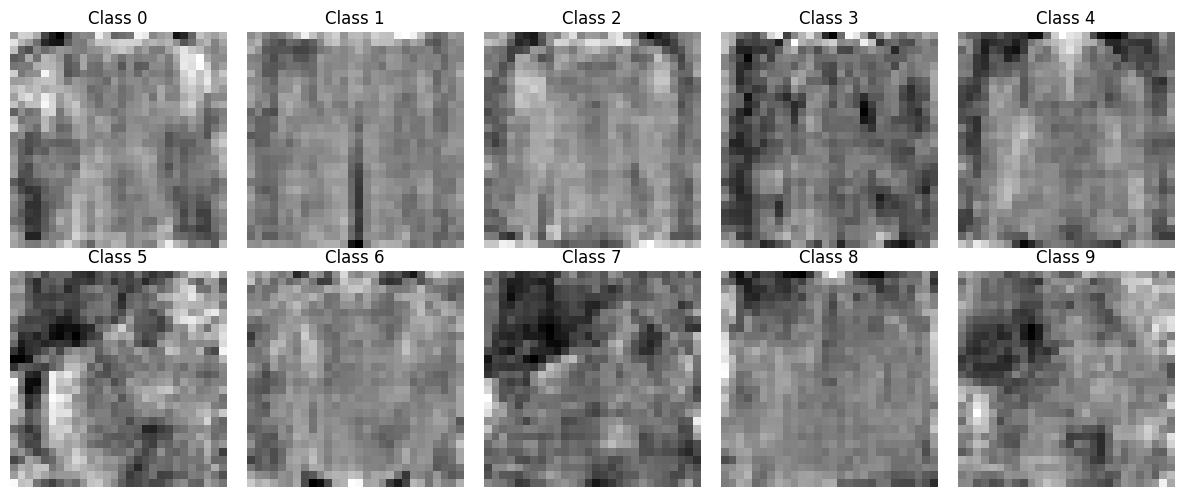

In [53]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.flat):

    reconstructed = reconstruct_image(class_id)
    reconstructed = reconstructed.reshape(28, 28)

    ax.imshow(reconstructed, cmap='gray')
    ax.set_title(f'Class {class_id}')
    ax.axis('off')

plt.tight_layout()
plt.show()

## Stage 3

def reconstruct_image(image_index):
    z = z_test[image_index]

    h1_hat = relu(W2.T @ z)

    x_hat = sigmoid(W1.T @ h1_hat)

    return x_hat

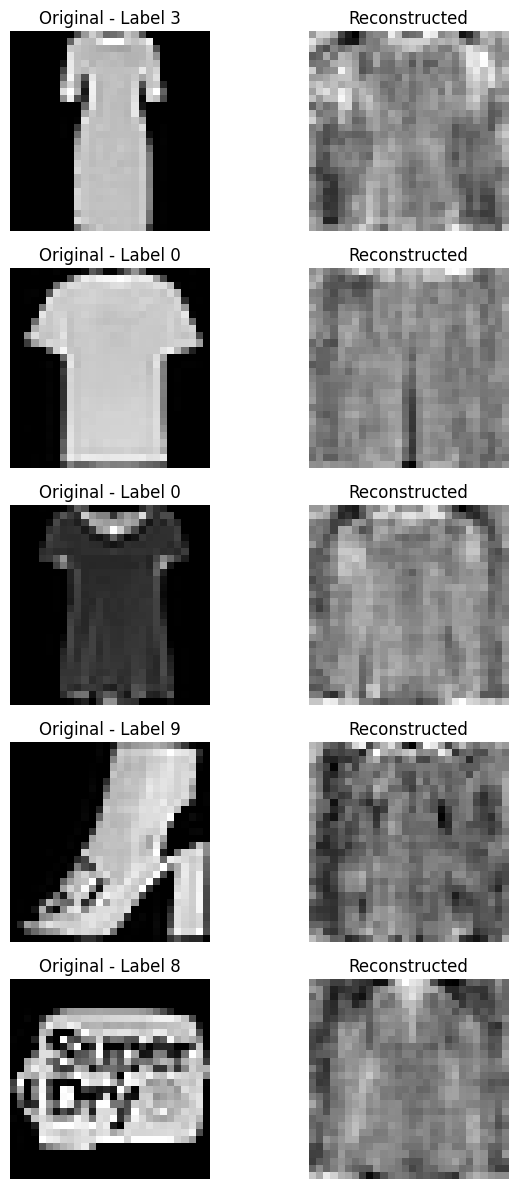

In [54]:
fig, axes = plt.subplots(5, 2, figsize=(7, 12))

for i in range(5):

    original = test_dataset[i][0].squeeze().numpy()

    reconstructed = reconstruct_image(i).reshape(28, 28)

    axes[i, 0].imshow(original, cmap='gray')
    axes[i, 0].set_title(f'Original - Label {y_test[i]}')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(reconstructed, cmap='gray')
    axes[i, 1].set_title('Reconstructed')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

## Stage 4

In [55]:
for param in model.parameters():
    param.requires_grad = False

model.eval()

ImageMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [56]:
def extract_latent_and_images(loader):
    features = []
    images_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)

            z = latent_subnetwork(images)

            x = images.view(images.size(0), -1)

            features.append(z.cpu())
            images_list.append(x.cpu())

    return (
        torch.cat(features),
        torch.cat(images_list)
    )


In [57]:
z_train, x_train = extract_latent_and_images(train_loader)
z_test, x_test = extract_latent_and_images(test_loader)

In [58]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),

            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.network(z)


decoder = Decoder().to(device)

In [59]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(z_train, x_train)

train_decoder_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    decoder.parameters(),
    lr=0.001
)

epochs = 30

for epoch in range(epochs):

    decoder.train()
    total_loss = 0

    for z, x in train_decoder_loader:

        z = z.to(device)
        x = x.to(device)

        reconstructed = decoder(z)

        loss = criterion(reconstructed, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_decoder_loader)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.6f}"
    )

Epoch [1/30] Loss: 0.040112
Epoch [2/30] Loss: 0.028037
Epoch [3/30] Loss: 0.025283
Epoch [4/30] Loss: 0.023806
Epoch [5/30] Loss: 0.022775
Epoch [6/30] Loss: 0.022087
Epoch [7/30] Loss: 0.021529
Epoch [8/30] Loss: 0.021111
Epoch [9/30] Loss: 0.020649
Epoch [10/30] Loss: 0.020354
Epoch [11/30] Loss: 0.020030
Epoch [12/30] Loss: 0.019800
Epoch [13/30] Loss: 0.019622
Epoch [14/30] Loss: 0.019401
Epoch [15/30] Loss: 0.019261
Epoch [16/30] Loss: 0.019063
Epoch [17/30] Loss: 0.018958
Epoch [18/30] Loss: 0.018778
Epoch [19/30] Loss: 0.018708
Epoch [20/30] Loss: 0.018611
Epoch [21/30] Loss: 0.018474
Epoch [22/30] Loss: 0.018395
Epoch [23/30] Loss: 0.018338
Epoch [24/30] Loss: 0.018226
Epoch [25/30] Loss: 0.018142
Epoch [26/30] Loss: 0.018084
Epoch [27/30] Loss: 0.017986
Epoch [28/30] Loss: 0.017957
Epoch [29/30] Loss: 0.017920
Epoch [30/30] Loss: 0.017833


In [60]:
def evaluate_reconstruction(decoder, z_data, x_data):

    decoder.eval()

    with torch.no_grad():
        z = z_data.to(device)
        reconstructed = decoder(z).cpu().numpy()

    original = x_data.numpy()

    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    for i in range(len(original)):

        original_img = original[i].reshape(28, 28)
        reconstructed_img = reconstructed[i].reshape(28, 28)

        mse = np.mean(
            (original_img - reconstructed_img) ** 2
        )

        psnr = peak_signal_noise_ratio(
            original_img,
            reconstructed_img,
            data_range=1.0
        )

        ssim = structural_similarity(
            original_img,
            reconstructed_img,
            data_range=1.0
        )

        mse_scores.append(mse)
        psnr_scores.append(psnr)
        ssim_scores.append(ssim)

    return {
        "MSE": np.mean(mse_scores),
        "PSNR": np.mean(psnr_scores),
        "SSIM": np.mean(ssim_scores)
    }

In [61]:

mlp_decoder_metrics = evaluate_reconstruction(
    decoder,
    z_test,
    x_test
)

print("MLP Frozen Latent Decoder:")
print(mlp_decoder_metrics)

MLP Frozen Latent Decoder:
{'MSE': np.float32(0.018405197), 'PSNR': np.float64(18.15357724213391), 'SSIM': np.float64(0.6510442906404013)}


In [62]:
class Autoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 64)
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),

            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):

        z = self.encoder(x)
        reconstructed = self.decoder(z)

        return reconstructed

In [63]:
autoencoder = Autoencoder().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    autoencoder.parameters(),
    lr=0.001
)

# Original training images
x_train_loader = DataLoader(
    x_train,
    batch_size=128,
    shuffle=True
)

epochs = 30

for epoch in range(epochs):

    autoencoder.train()
    total_loss = 0

    for x in x_train_loader:

        x = x.to(device)

        reconstructed = autoencoder(x)

        loss = criterion(reconstructed, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {total_loss / len(x_train_loader):.6f}"
    )

Epoch [1/30] Loss: 0.032452
Epoch [2/30] Loss: 0.016815
Epoch [3/30] Loss: 0.014100
Epoch [4/30] Loss: 0.012439
Epoch [5/30] Loss: 0.011397
Epoch [6/30] Loss: 0.010618
Epoch [7/30] Loss: 0.010024
Epoch [8/30] Loss: 0.009509
Epoch [9/30] Loss: 0.009109
Epoch [10/30] Loss: 0.008740
Epoch [11/30] Loss: 0.008462
Epoch [12/30] Loss: 0.008219
Epoch [13/30] Loss: 0.007974
Epoch [14/30] Loss: 0.007799
Epoch [15/30] Loss: 0.007615
Epoch [16/30] Loss: 0.007467
Epoch [17/30] Loss: 0.007313
Epoch [18/30] Loss: 0.007194
Epoch [19/30] Loss: 0.007065
Epoch [20/30] Loss: 0.006960
Epoch [21/30] Loss: 0.006874
Epoch [22/30] Loss: 0.006783
Epoch [23/30] Loss: 0.006711
Epoch [24/30] Loss: 0.006629
Epoch [25/30] Loss: 0.006573
Epoch [26/30] Loss: 0.006514
Epoch [27/30] Loss: 0.006465
Epoch [28/30] Loss: 0.006413
Epoch [29/30] Loss: 0.006375
Epoch [30/30] Loss: 0.006329


In [64]:
# Re-training Vanilla Autoencoder to track time and losses (or simulating it if already trained)
autoencoder = Autoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)

x_train_loader = DataLoader(x_train, batch_size=128, shuffle=True)
epochs = 30
ae_losses = []
start_train_ae = time.time()

for epoch in range(epochs):
    autoencoder.train()
    total_loss = 0
    for x in x_train_loader:
        x = x.to(device)
        reconstructed = autoencoder(x)
        loss = criterion(reconstructed, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(x_train_loader)
    ae_losses.append(avg_loss)

time_per_epoch_ae = (time.time() - start_train_ae) / epochs

print(f"Vanilla AE - Time/Epoch: {time_per_epoch_ae:.2f}s")

Vanilla AE - Time/Epoch: 1.27s


In [65]:
def evaluate_autoencoder(model, x_data):

    model.eval()

    with torch.no_grad():
        reconstructed = model(
            x_data.to(device)
        ).cpu()

    # Reuse the same evaluation logic
    class TemporaryDecoder:
        pass

    temp = TemporaryDecoder()

    # Easier alternative: calculate metrics directly
    original = x_data.numpy()
    reconstructed = reconstructed.numpy()

    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    for i in range(len(original)):

        original_img = original[i].reshape(28, 28)
        reconstructed_img = reconstructed[i].reshape(28, 28)

        mse_scores.append(
            np.mean((original_img - reconstructed_img) ** 2)
        )

        psnr_scores.append(
            peak_signal_noise_ratio(
                original_img, reconstructed_img, data_range=1.0
            )
        )

        ssim_scores.append(
            structural_similarity(
                original_img, reconstructed_img, data_range=1.0
            )
        )

    return {
        "MSE": np.mean(mse_scores),
        "PSNR": np.mean(psnr_scores),
        "SSIM": np.mean(ssim_scores)
    }


ae_metrics = evaluate_autoencoder(
    autoencoder,
    x_test
)

In [66]:
import pandas as pd

comparison = pd.DataFrame(
    [mlp_decoder_metrics, ae_metrics],
    index=[
        "MLP Frozen Latent Decoder",
        "Vanilla Autoencoder"
    ]
)

print(comparison)

                                MSE       PSNR      SSIM
MLP Frozen Latent Decoder  0.018405  18.153577  0.651044
Vanilla Autoencoder        0.006517  22.998489  0.829232


## Stage 5

In [67]:
mu_z = torch.mean(z_test, dim=0)
sigma_z = torch.std(z_test, dim=0)

print("Mean shape:", mu_z.shape)
print("Std shape:", sigma_z.shape)

Mean shape: torch.Size([64])
Std shape: torch.Size([64])


In [68]:
# Number of images to generate
num_samples = 20

# Generate random latent vectors
z_random = np.random.normal(
    loc=mu_z,
    scale=sigma_z,
    size=(num_samples, 64)
)

print("Random latent shape:", z_random.shape)

Random latent shape: (20, 64)


In [69]:
# Convert NumPy array to PyTorch tensor
z_random_tensor = torch.tensor(
    z_random,
    dtype=torch.float32
).to(device)

# Generate images
decoder.eval()

with torch.no_grad():
    generated_images = decoder(z_random_tensor)

generated_images = generated_images.cpu().numpy()

print("Generated images:", generated_images.shape)

Generated images: (20, 784)


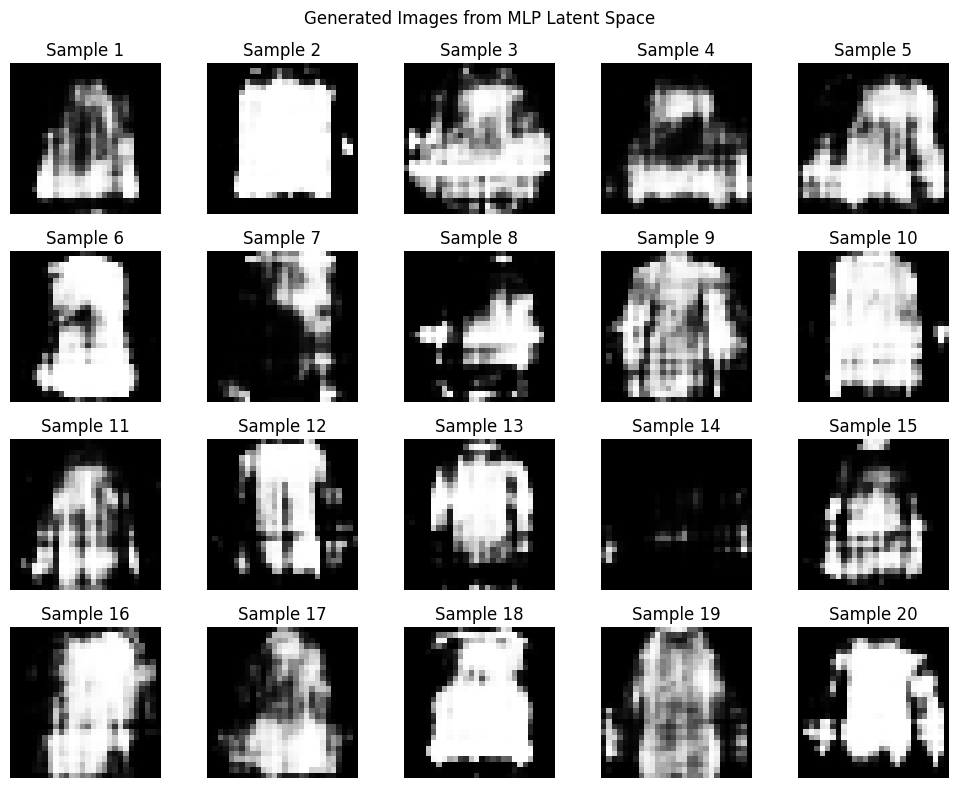

In [70]:
fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for i, ax in enumerate(axes.flat):

    image = generated_images[i].reshape(28, 28)

    ax.imshow(image, cmap='gray')
    ax.set_title(f"Sample {i+1}")
    ax.axis('off')

plt.suptitle("Generated Images from MLP Latent Space")
plt.tight_layout()
plt.show()

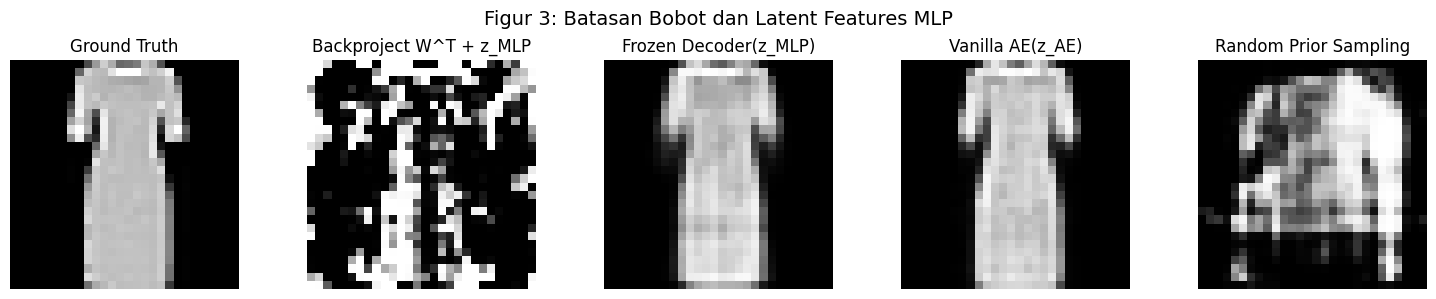

In [71]:
original_idx = 0
orig_img = x_test[original_idx].numpy().reshape(28, 28)
label = y_test[original_idx]

z_np = z_test[original_idx].numpy()
h1_hat = relu(W2.T @ z_np)
x_hat = sigmoid(W1.T @ h1_hat)
reconstructed_analytic = x_hat.reshape(28, 28)

z_mlp_sample = z_test[original_idx].to(device)
x_ae_sample = x_test[original_idx].to(device)

with torch.no_grad():
    recon_mlp_decoder = decoder(z_mlp_sample).cpu().numpy().reshape(28, 28)
    recon_ae = autoencoder(x_ae_sample).cpu().numpy().reshape(28, 28)

z_rand = np.random.normal(loc=mu_z.numpy(), scale=sigma_z.numpy(), size=(1, 64))
z_rand_tensor = torch.tensor(z_rand, dtype=torch.float32).to(device)
with torch.no_grad():
    recon_rand = decoder(z_rand_tensor).cpu().numpy().reshape(28, 28)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(orig_img, cmap='gray'); axes[0].set_title('Ground Truth')
axes[1].imshow(reconstructed_analytic, cmap='gray'); axes[1].set_title('Backproject W^T + z_MLP')
axes[2].imshow(recon_mlp_decoder, cmap='gray'); axes[2].set_title('Frozen Decoder(z_MLP)')
axes[3].imshow(recon_ae, cmap='gray'); axes[3].set_title('Vanilla AE(z_AE)')
axes[4].imshow(recon_rand, cmap='gray'); axes[4].set_title('Random Prior Sampling')

for ax in axes:
    ax.axis('off')
plt.suptitle('Figur 3: Batasan Bobot dan Latent Features MLP', fontsize=14)
plt.tight_layout()
plt.savefig('figur_3.png')
plt.show()